In [1]:
# # STEP 1 - Install required libraries (run once)
# !pip install kagglehub pandas scikit-learn matplotlib pillow seaborn -q

# # STEP 2 - Download the dataset
# # NOTE (local / VS Code setup): place your Kaggle API token 'kaggle.json' at
# #   Windows: C:\Users\<YourName>\.kaggle\kaggle.json
# #   Mac/Linux: ~/.kaggle/kaggle.json
# # Get the token from kaggle.com -> profile -> Settings -> API -> Create New Token.
# # kagglehub reads it automatically, so no upload step is needed.
# import kagglehub
# path = kagglehub.dataset_download("ambarish/breakhis")
# print("Dataset downloaded to:", path)

In [2]:
# ===== COLAB SETUP - run this INSTEAD of the cell above =====
# In Colab, skip cell 0 entirely; this cell replaces it.

# 1) Libraries. -U matters: Colab's bundled kagglehub can be out of date.
!pip install -q -U kagglehub seaborn

# 2) Kaggle auth from Colab Secrets. Sidebar key icon -> add KAGGLE_USERNAME
#    and KAGGLE_KEY (the two values inside kaggle.json) -> enable notebook
#    access. Set once and it survives every future session: no re-upload.
import os
from google.colab import userdata
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"]      = userdata.get("KAGGLE_KEY")

# 3) Mount Drive so results, checkpoints and runtimes survive a disconnect.
from google.colab import drive
drive.mount("/content/drive")

# 4) Confirm the GPU is active: Runtime -> Change runtime type -> T4 GPU
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("GPUs available:", gpus)
if not gpus:
    print("WARNING: no GPU detected. Runtime -> Change runtime type -> T4 GPU.")

# 5) Download the dataset. It stays on fast local disk, NOT on Drive -
#    reading 7,909 small PNGs through the Drive mount is far slower.
import kagglehub
path = kagglehub.dataset_download("ambarish/breakhis")
print("Path to dataset files:", path)

Mounted at /content/drive
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using Colab cache for faster access to the 'breakhis' dataset.
Path to dataset files: /kaggle/input/breakhis


In [3]:
# --- per-cell runtime logging: run this cell ONCE ---
import time, pandas as pd
from IPython import get_ipython
CELL_TIMES, _s = [], {"n": 0}
def _pre(info): _s["t"], _s["n"] = time.perf_counter(), _s["n"] + 1
def _post(res):
    if "t" not in _s: return                      # skips this setup cell itself
    dt = time.perf_counter() - _s.pop("t")   # pop: an empty cell can fire post w/o pre
    CELL_TIMES.append({"cell": _s["n"], "seconds": round(dt, 3),
                       "label": ((res.info.raw_cell or "").strip().splitlines() or [""])[0][:55]})
    print(f"[cell {_s['n']}] runtime: {dt:.2f}s")
def runtime_table():
    df = pd.DataFrame(CELL_TIMES); df.to_csv(OUTPUT_DIR / "cell_runtimes_oversampling.csv", index=False); return df
get_ipython().events.register("pre_run_cell", _pre)
get_ipython().events.register("post_run_cell", _post)

# 1 Dataset Loading

In [4]:
import kagglehub
import os, pathlib, shutil

# Download BreakHis dataset via KaggleHub
path = kagglehub.dataset_download("ambarish/breakhis")
print("Dataset downloaded to:", path)

# Walk the top-level structure
print("\nTop-level directory contents:")
for item in sorted(os.listdir(path)):
    print(" ", item)

Using Colab cache for faster access to the 'breakhis' dataset.
Dataset downloaded to: /kaggle/input/breakhis

Top-level directory contents:
  BreaKHis_v1
  Folds.csv
[cell 1] runtime: 0.84s


In [5]:
import pandas as pd
import numpy as np
from pathlib import Path

DATASET_ROOT = Path(path)
# Local output folder, created next to this notebook (Colab used a different path).
OUTPUT_DIR   = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".bmp"}

# Recursively discover all image files
records = []
for img_path in DATASET_ROOT.rglob("*"):
    if img_path.suffix.lower() in IMG_EXTENSIONS:
        # Determine class from parent folder structure
        # BreakHis structure: .../breast/benign/... or .../breast/malignant/...
        parts = img_path.parts
        label = None
        for part in parts:
            if part.lower() == "benign":
                label = "benign"
                break
            elif part.lower() == "malignant":
                label = "malignant"
                break
        if label is not None:
            records.append({"image_path": str(img_path), "class_label": label})

df = pd.DataFrame(records)
print(f"Total images found: {len(df)}")
print(df["class_label"].value_counts())
df.head()

Total images found: 7909
class_label
malignant    5429
benign       2480
Name: count, dtype: int64


,image_path,class_label
0,/kaggle/input/breakhis/BreaKHis_v1/BreaKHis_v1...,malignant
1,/kaggle/input/breakhis/BreaKHis_v1/BreaKHis_v1...,malignant
2,/kaggle/input/breakhis/BreaKHis_v1/BreaKHis_v1...,malignant
3,/kaggle/input/breakhis/BreaKHis_v1/BreaKHis_v1...,malignant
4,/kaggle/input/breakhis/BreaKHis_v1/BreaKHis_v1...,malignant


[cell 2] runtime: 7.46s


In [6]:
# ===== COLAB: send all outputs to Drive =====
# Must run AFTER the cell above, which sets OUTPUT_DIR to an ephemeral local
# path that Colab wipes when the runtime recycles. This re-points it at Drive.
# Both notebooks use the SAME folder, so the Section 12 oversampling-vs-
# undersampling comparison can finally find both results CSVs.
OUTPUT_DIR = Path("/content/drive/MyDrive/breakhis_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("OUTPUT_DIR ->", OUTPUT_DIR)
print("Dataset stays on local disk ->", DATASET_ROOT)

OUTPUT_DIR -> /content/drive/MyDrive/breakhis_outputs
Dataset stays on local disk -> /kaggle/input/breakhis
[cell 3] runtime: 0.33s


# 2 Dataset Exploration

In [7]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random, warnings
warnings.filterwarnings("ignore")

print("=" * 55)
print("DATASET SUMMARY")
print("=" * 55)
print(f"Total images          : {len(df)}")
print(f"Classes               : {df['class_label'].unique().tolist()}")
print(f"Benign images         : {(df['class_label']=='benign').sum()}")
print(f"Malignant images      : {(df['class_label']=='malignant').sum()}")
print(f"Class imbalance ratio : {(df['class_label']=='malignant').sum()/(df['class_label']=='benign').sum():.2f}")
print("=" * 55)

DATASET SUMMARY
Total images          : 7909
Classes               : ['malignant', 'benign']
Benign images         : 2480
Malignant images      : 5429
Class imbalance ratio : 2.19
[cell 4] runtime: 0.03s


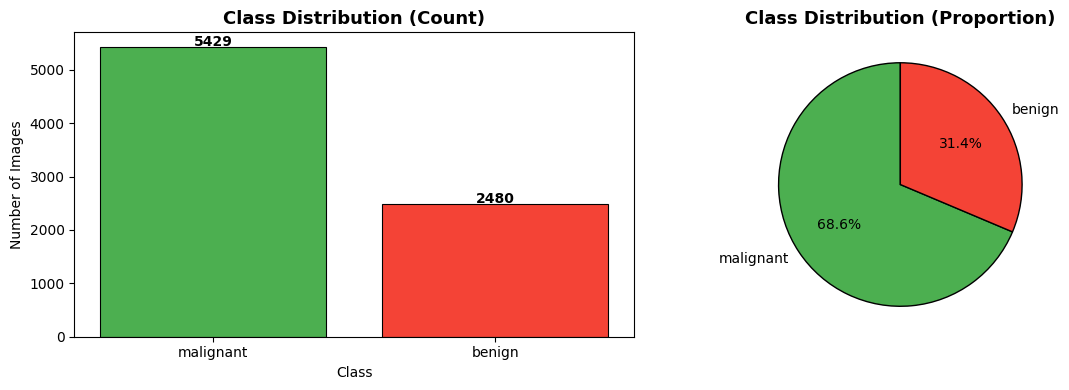

[cell 5] runtime: 1.15s


In [8]:
# Class distribution chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = df["class_label"].value_counts()
colors = ["#4CAF50", "#F44336"]

axes[0].bar(counts.index, counts.values, color=colors, edgecolor="black", linewidth=0.8)
axes[0].set_title("Class Distribution (Count)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of Images")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, str(v), ha="center", fontweight="bold")

axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%",
            colors=colors, startangle=90, wedgeprops={"edgecolor": "black"})
axes[1].set_title("Class Distribution (Proportion)", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

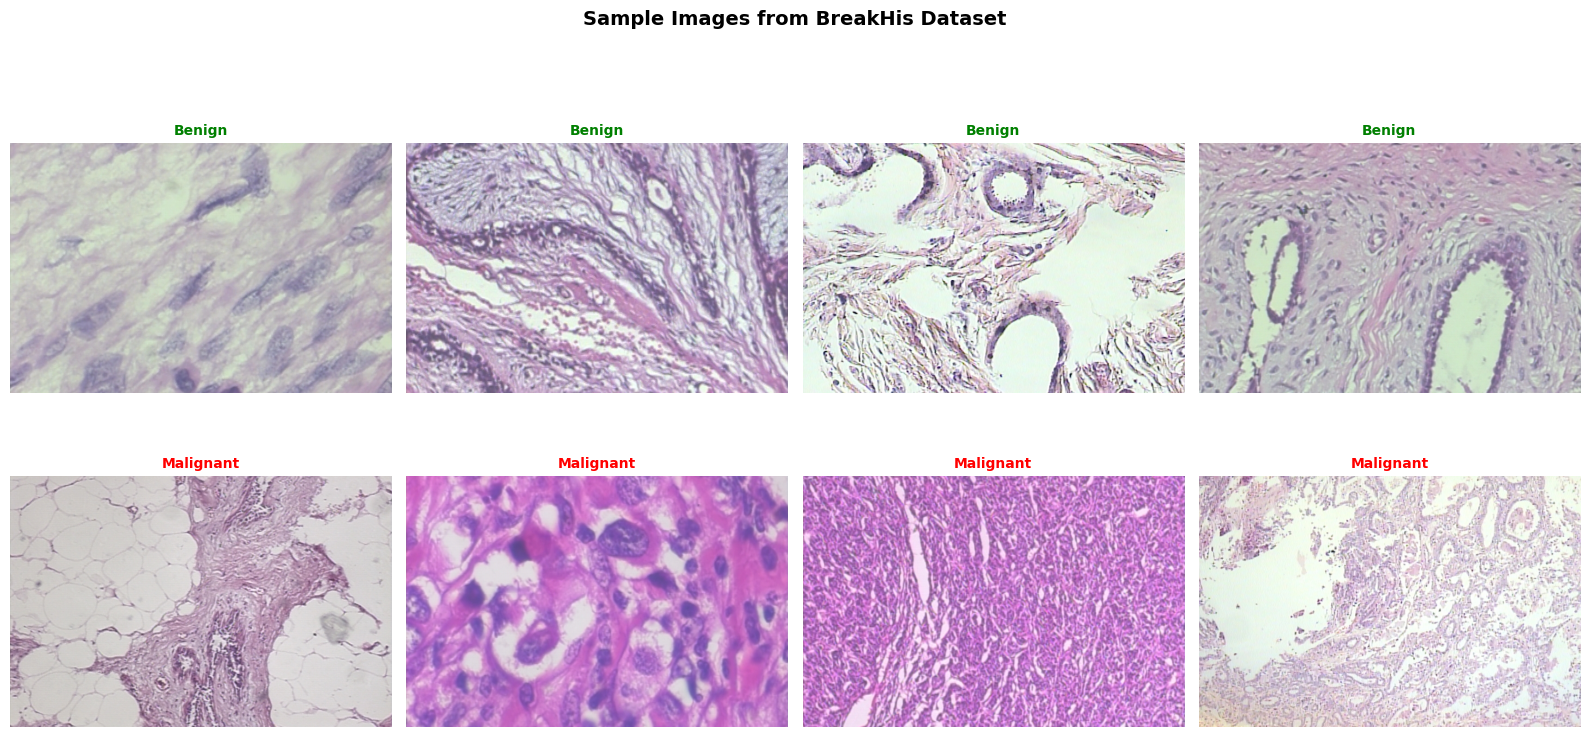

[cell 6] runtime: 7.95s


In [9]:
# Random image visualization (4 benign + 4 malignant)
benign_samples    = df[df["class_label"] == "benign"].sample(4, random_state=42)
malignant_samples = df[df["class_label"] == "malignant"].sample(4, random_state=42)
samples = pd.concat([benign_samples, malignant_samples])

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (_, row) in zip(axes.flatten(), samples.iterrows()):
    try:
        img = mpimg.imread(row["image_path"])
        ax.imshow(img)
        ax.set_title(row["class_label"].capitalize(), fontsize=10,
                     color="green" if row["class_label"] == "benign" else "red",
                     fontweight="bold")
    except Exception:
        ax.set_title("Error", color="grey")
    ax.axis("off")

plt.suptitle("Sample Images from BreakHis Dataset", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# Dataset summary table
summary = pd.DataFrame({
    "Metric": ["Total Images", "Benign", "Malignant", "Image Extensions"],
    "Value": [
        len(df),
        (df["class_label"] == "benign").sum(),
        (df["class_label"] == "malignant").sum(),
        ", ".join(df["image_path"].apply(lambda x: Path(x).suffix.lower()).unique())
    ]
})
print(summary.to_string(index=False))

          Metric Value
    Total Images  7909
          Benign  2480
       Malignant  5429
Image Extensions  .png
[cell 7] runtime: 0.45s


# 3 Data Cleaning

In [11]:
from PIL import Image
import io

def is_valid_image(path):
    """Return True if image can be opened and decoded correctly."""
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

print("Scanning for corrupted images...")
df["is_valid"] = df["image_path"].apply(is_valid_image)

invalid_count = (~df["is_valid"]).sum()
print(f"Total images  : {len(df)}")
print(f"Valid images  : {df['is_valid'].sum()}")
print(f"Invalid images: {invalid_count}")

Scanning for corrupted images...
Total images  : 7909
Valid images  : 7909
Invalid images: 0
[cell 8] runtime: 55.04s


In [12]:
# Remove invalid images
df_clean = df[df["is_valid"]].copy().reset_index(drop=True)
df_clean.drop(columns=["is_valid"], inplace=True)

print(f"Dataset after cleaning: {len(df_clean)} images")
print(df_clean["class_label"].value_counts())

Dataset after cleaning: 7909 images
class_label
malignant    5429
benign       2480
Name: count, dtype: int64
[cell 9] runtime: 0.01s


# 4 Data Preprocessing

In [13]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array

IMG_SIZE    = (224, 224)
BATCH_SIZE  = 32
NUM_CLASSES = 1   # binary classification

# Label encoding: benign=0, malignant=1
df_clean["label"] = (df_clean["class_label"] == "malignant").astype(int)

print("Label distribution:")
print(df_clean["label"].value_counts())
print(f"\nImage target size: {IMG_SIZE}")
print(f"Batch size       : {BATCH_SIZE}")

Label distribution:
label
1    5429
0    2480
Name: count, dtype: int64

Image target size: (224, 224)
Batch size       : 32
[cell 10] runtime: 0.01s


In [14]:
# Verify a single image load + normalise pipeline
sample_path = df_clean["image_path"].iloc[0]
img = load_img(sample_path, target_size=IMG_SIZE)
arr = img_to_array(img) / 255.0
print(f"Sample image shape : {arr.shape}")
print(f"Pixel value range  : [{arr.min():.3f}, {arr.max():.3f}]")

Sample image shape : (224, 224, 3)
Pixel value range  : [0.188, 1.000]
[cell 11] runtime: 0.02s


# 5 Data Augmentation

In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Training augmentation
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    fill_mode="nearest"
)

# Validation / test — only rescale
val_test_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

print("Training augmentation configuration:")
print("  Rescale          : 1/255")
print("  Rotation range   : 20 degrees")
print("  Horizontal flip  : True")
print("  Zoom range       : 0.15")
print("  Width shift      : 0.1")
print("  Height shift     : 0.1")

Training augmentation configuration:
  Rescale          : 1/255
  Rotation range   : 20 degrees
  Horizontal flip  : True
  Zoom range       : 0.15
  Width shift      : 0.1
  Height shift     : 0.1
[cell 12] runtime: 0.00s


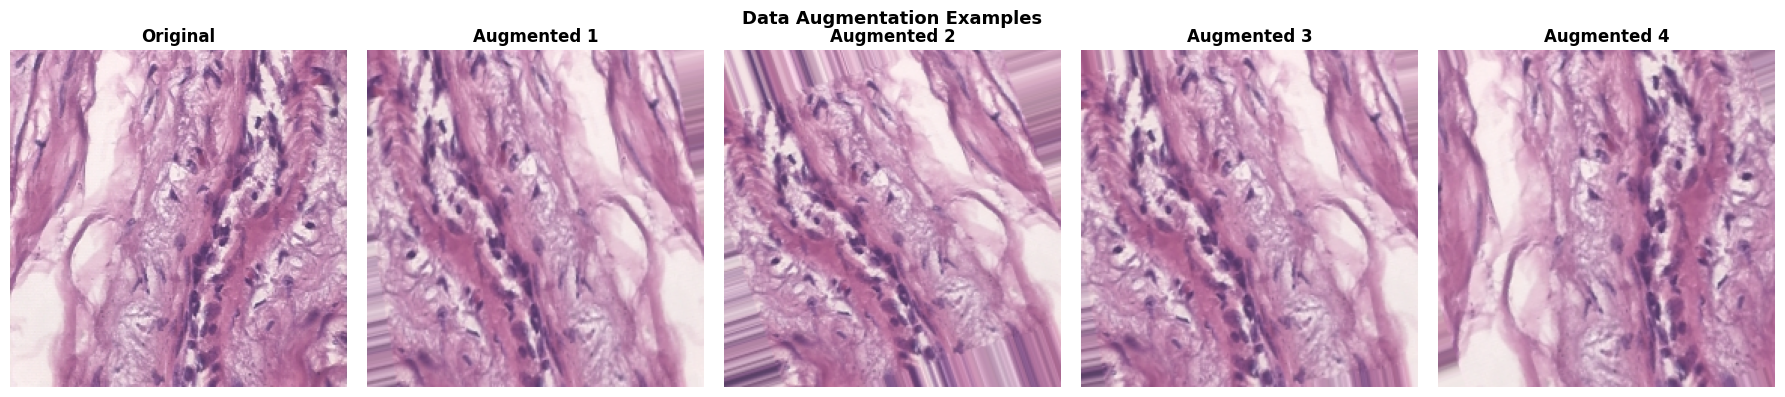

[cell 13] runtime: 1.96s


In [16]:
# Visualise augmented samples
sample_img_path = df_clean[df_clean["class_label"] == "malignant"]["image_path"].iloc[0]
orig_img = load_img(sample_img_path, target_size=IMG_SIZE)
orig_arr = img_to_array(orig_img)
orig_arr_exp = orig_arr.reshape((1,) + orig_arr.shape)

aug_gen = ImageDataGenerator(
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.15,
    fill_mode="nearest"
)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(orig_arr.astype("uint8"))
axes[0].set_title("Original", fontweight="bold")
axes[0].axis("off")

for i, batch in enumerate(aug_gen.flow(orig_arr_exp, batch_size=1)):
    axes[i + 1].imshow(batch[0].astype("uint8"))
    axes[i + 1].set_title(f"Augmented {i+1}", fontweight="bold")
    axes[i + 1].axis("off")
    if i == 3:
        break

plt.suptitle("Data Augmentation Examples", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

# 6 Train Validation Test Split

In [17]:
from sklearn.model_selection import train_test_split

# Stratified split: 70% train, 15% val, 15% test
df_train, df_temp = train_test_split(
    df_clean, test_size=0.30, stratify=df_clean["label"], random_state=42
)
df_val, df_test = train_test_split(
    df_temp, test_size=0.50, stratify=df_temp["label"], random_state=42
)

print(f"Training set   : {len(df_train)} images  | benign={( df_train['label']==0).sum()}  malignant={( df_train['label']==1).sum()}")
print(f"Validation set : {len(df_val)} images  | benign={( df_val['label']==0).sum()}  malignant={( df_val['label']==1).sum()}")
print(f"Test set       : {len(df_test)} images  | benign={( df_test['label']==0).sum()}  malignant={( df_test['label']==1).sum()}")
print(f"\nTotal         : {len(df_train)+len(df_val)+len(df_test)} images")

Training set   : 5536 images  | benign=1736  malignant=3800
Validation set : 1186 images  | benign=372  malignant=814
Test set       : 1187 images  | benign=372  malignant=815

Total         : 7909 images
[cell 14] runtime: 0.29s


# 7 Class Balancing

In [18]:
# 7 Class Balancing - OVERSAMPLING (training set only)
# IMPORTANT: we balance ONLY the training data. Validation and test keep their
# natural (real-world) class distribution so the evaluation stays honest.
from sklearn.utils import resample

counts = df_train["label"].value_counts()
maj_label, min_label = counts.idxmax(), counts.idxmin()
df_maj = df_train[df_train["label"] == maj_label]
df_min = df_train[df_train["label"] == min_label]

# Oversample the minority class (with replacement) up to the majority count.
df_min_over = resample(df_min, replace=True, n_samples=len(df_maj), random_state=42)
df_train_bal = (pd.concat([df_maj, df_min_over])
                .sample(frac=1, random_state=42)
                .reset_index(drop=True))

print("Before balancing:")
print(df_train["label"].value_counts())
print("\nAfter OVERSAMPLING:")
print(df_train_bal["label"].value_counts())

SAMPLING_METHOD = "Oversampling"

Before balancing:
label
1    3800
0    1736
Name: count, dtype: int64

After OVERSAMPLING:
label
0    3800
1    3800
Name: count, dtype: int64
[cell 15] runtime: 0.01s


In [19]:
# Create generators. Training uses the BALANCED dataframe; validation/test unchanged.
df_train_bal["label_str"] = df_train_bal["class_label"]
df_val["label_str"]  = df_val["class_label"]
df_test["label_str"] = df_test["class_label"]

train_generator = train_datagen.flow_from_dataframe(
    df_train_bal, x_col="image_path", y_col="label_str",
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="binary", shuffle=True, seed=42)
val_generator = val_test_datagen.flow_from_dataframe(
    df_val, x_col="image_path", y_col="label_str",
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="binary", shuffle=False)
test_generator = val_test_datagen.flow_from_dataframe(
    df_test, x_col="image_path", y_col="label_str",
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="binary", shuffle=False)
print("Class indices:", train_generator.class_indices)

Found 7600 validated image filenames belonging to 2 classes.
Found 1186 validated image filenames belonging to 2 classes.
Found 1187 validated image filenames belonging to 2 classes.
Class indices: {'benign': 0, 'malignant': 1}
[cell 16] runtime: 2.60s


# 8 Hyperparameters

In [20]:
# 8 Hyperparameters
from tensorflow.keras import callbacks

HP = {
    "img_size":      IMG_SIZE,
    "batch_size":    BATCH_SIZE,
    "epochs":        15,
    "learning_rate": 1e-4,
    "dropout":       0.5,
    "optimizer":     "adam",
}
print("Hyperparameters:")
for k, v in HP.items():
    print(f"  {k}: {v}")

# Callbacks are part of hyperparameter control: EarlyStopping prevents overfitting,
# ReduceLROnPlateau adapts the learning rate, ModelCheckpoint keeps the best weights.
def make_callbacks(tag):
    return [
        callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
        callbacks.ModelCheckpoint(filepath=str(OUTPUT_DIR / f"best_{tag}_{SAMPLING_METHOD}.keras"),
                                  monitor="val_accuracy", mode="max", save_best_only=True),
    ]

Hyperparameters:
  img_size: (224, 224)
  batch_size: 32
  epochs: 15
  learning_rate: 0.0001
  dropout: 0.5
  optimizer: adam
[cell 17] runtime: 0.00s


# 9 Models (Custom CNN, DenseNet121, MobileNetV2)

In [21]:
# 9 Models: Custom CNN (your baseline) + two transfer-learning models
from tensorflow.keras import layers, Model, optimizers
from tensorflow.keras.applications import DenseNet121, MobileNetV2

def build_custom_cnn():
    inputs = layers.Input(shape=(224, 224, 3))
    x = inputs
    for f in [32, 64, 128, 256]:
        x = layers.Conv2D(f, (3, 3), activation="relu", padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(HP["dropout"])(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return Model(inputs, outputs, name="CustomCNN")

def build_transfer(base_fn, name):
    base = base_fn(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
    base.trainable = False                      # freeze the pretrained backbone
    inputs = layers.Input(shape=(224, 224, 3))
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(HP["dropout"])(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return Model(inputs, outputs, name=name)

def build_models():
    return {
        "CustomCNN":   build_custom_cnn(),
        "DenseNet121": build_transfer(DenseNet121, "DenseNet121"),
        "MobileNetV2": build_transfer(MobileNetV2, "MobileNetV2"),
    }

# NOTE: these models use the 1/255-rescaled generators above. To swap in
# EfficientNet or ConvNeXt, remove the 1/255 rescale and use that model's
# own preprocess_input instead, as they expect differently-scaled inputs.

[cell 18] runtime: 0.00s


# 10 Model Training

In [22]:
# 10 Training all three models
models = build_models()
histories = {}
for name, model in models.items():
    print("\n" + "=" * 60)
    print("Training:", name, "|", SAMPLING_METHOD)
    print("=" * 60)
    model.compile(optimizer=optimizers.Adam(HP["learning_rate"]),
                  loss="binary_crossentropy", metrics=["accuracy"])
    histories[name] = model.fit(
        train_generator, validation_data=val_generator,
        epochs=HP["epochs"], callbacks=make_callbacks(name), verbose=1)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Training: CustomCNN | Oversampling
Epoch 1/15
238/238 ━━━━━━━━━━━━━━━━━━━━ 244s 977ms/step - accuracy: 0.8088 - loss: 0.4219 - val_accuracy: 0.6863 - val_loss: 0.7740 - learning_rate: 1.0000e-04
Epoch 2/15
238/238 ━━━━━━━━━━━━━━━━━━━━ 228s 954ms/step - accuracy: 0.8570 - loss: 0.3258 - val_accuracy: 0.8533 - val_loss: 0.3733 - learning_rate: 1.0000e-04
Epoch 3/15
238/238 ━━━━━━━━━━━━━━━━━━━━ 224s 940ms/step - accuracy: 0.8754 - loss: 0.2912 - val_accuracy: 0.8735 - val_loss: 0.3162 - learning_rate: 1.0000e-04
Epoch 4/15
238/238 ━━━━━━━━━━━━━━━━━━━━ 221s 931ms/step - accuracy: 0.8896 - loss: 0.2663 - val_accuracy: 0.8752 - val_loss: 0.3038 - learning_rate: 1.0000e-04
Epoch 5/15
238/238 ━━━━━━━━━━━━━━━━━━━━ 223s 937ms/step - accuracy: 0.8930 - loss: 0.2548 - val_accuracy: 0.9022 - val_loss: 0.2472 - learning_rate: 1.0000e-04
Epoch 6/15
238/238 ━━━━━━━━━━━━━━━━━━━━ 228s 958ms/step - accura

# 11 Performance Metrics


CustomCNN - classification report

              precision    recall  f1-score   support

      Benign       0.79      0.91      0.84       372
   Malignant       0.95      0.89      0.92       815

    accuracy                           0.89      1187
   macro avg       0.87      0.90      0.88      1187
weighted avg       0.90      0.89      0.89      1187



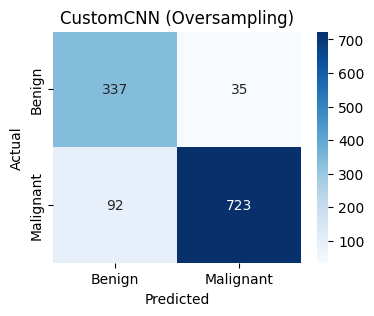


DenseNet121 - classification report

              precision    recall  f1-score   support

      Benign       0.81      0.87      0.84       372
   Malignant       0.94      0.91      0.92       815

    accuracy                           0.90      1187
   macro avg       0.87      0.89      0.88      1187
weighted avg       0.90      0.90      0.90      1187



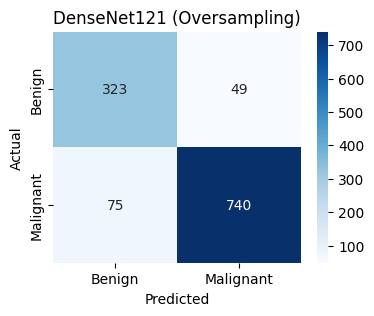


MobileNetV2 - classification report

              precision    recall  f1-score   support

      Benign       0.61      0.79      0.69       372
   Malignant       0.89      0.77      0.83       815

    accuracy                           0.78      1187
   macro avg       0.75      0.78      0.76      1187
weighted avg       0.80      0.78      0.78      1187



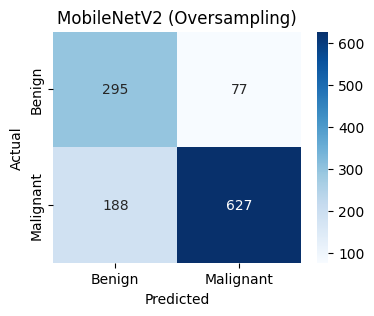


Performance summary (Oversampling):
      Model     Sampling  Accuracy  Precision  Recall     F1  ROC_AUC
  CustomCNN Oversampling    0.8930     0.9538  0.8871 0.9193   0.9673
DenseNet121 Oversampling    0.8955     0.9379  0.9080 0.9227   0.9522
MobileNetV2 Oversampling    0.7767     0.8906  0.7693 0.8255   0.8574
Saved: /content/drive/MyDrive/breakhis_outputs/results_oversampling.csv


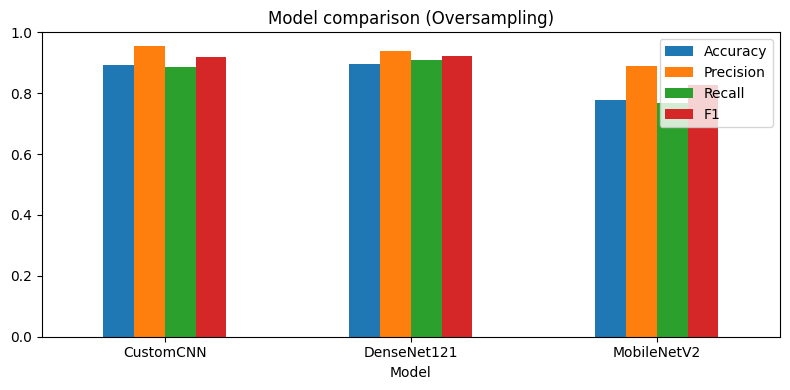

[cell 20] runtime: 114.16s


In [23]:
# 11 Performance Metrics (performance matrix)
import numpy as np
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report)

y_true = df_test["label"].astype(int).values
results = []
for name, model in models.items():
    test_generator.reset()
    probs = model.predict(test_generator, verbose=0).flatten()
    preds = (probs >= 0.5).astype(int)
    results.append({
        "Model": name, "Sampling": SAMPLING_METHOD,
        "Accuracy":  accuracy_score(y_true, preds),
        "Precision": precision_score(y_true, preds),
        "Recall":    recall_score(y_true, preds),
        "F1":        f1_score(y_true, preds),
        "ROC_AUC":   roc_auc_score(y_true, probs),
    })
    print("\n" + name + " - classification report\n")
    print(classification_report(y_true, preds, target_names=["Benign", "Malignant"]))
    cm = confusion_matrix(y_true, preds)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"])
    plt.title(f"{name} ({SAMPLING_METHOD})")
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

results_df = pd.DataFrame(results)
print("\nPerformance summary (" + SAMPLING_METHOD + "):")
print(results_df.round(4).to_string(index=False))

# save results so the over-vs-under comparison cell can pick them up
csv_path = OUTPUT_DIR / f"results_{SAMPLING_METHOD.lower()}.csv"
results_df.to_csv(csv_path, index=False)
print("Saved:", csv_path)

ax = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot.bar(figsize=(8, 4))
ax.set_title(f"Model comparison ({SAMPLING_METHOD})"); ax.set_ylim(0, 1)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# 12 Oversampling vs Undersampling Comparison

In [24]:
# 12 Comparison: Oversampling vs Undersampling
# Run BOTH notebooks (oversampling and undersampling) once each. They each save a
# results CSV into OUTPUT_DIR. This cell then loads both and compares them.
import os
paths = {"Oversampling": OUTPUT_DIR / "results_oversampling.csv",
         "Undersampling": OUTPUT_DIR / "results_undersampling.csv"}
frames = [pd.read_csv(p) for p in paths.values() if os.path.exists(p)]
if len(frames) < 2:
    print("Run BOTH the oversampling and undersampling notebooks first,")
    print("then re-run this cell to see the side-by-side comparison.")
else:
    comp = pd.concat(frames, ignore_index=True)
    print(comp.round(4).to_string(index=False))
    pivot = comp.pivot(index="Model", columns="Sampling", values="F1")
    ax = pivot.plot.bar(figsize=(8, 4))
    ax.set_title("Oversampling vs Undersampling - F1 by model")
    ax.set_ylim(0, 1); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

Run BOTH the oversampling and undersampling notebooks first,
then re-run this cell to see the side-by-side comparison.
[cell 21] runtime: 0.01s


In [25]:
# Per-cell runtime summary (written to OUTPUT_DIR)
df = runtime_table()
print(df.to_string(index=False))
print(f"\nTotal runtime: {df.seconds.sum():.1f}s ({df.seconds.sum()/60:.1f} min)")

 cell  seconds                                                   label
    1    0.839                                        import kagglehub
    2    7.459                                     import pandas as pd
    3    0.334          # ===== COLAB: send all outputs to Drive =====
    4    0.026                         import matplotlib.pyplot as plt
    5    1.147                              # Class distribution chart
    6    7.952   # Random image visualization (4 benign + 4 malignant)
    7    0.454                                 # Dataset summary table
    8   55.044                                   from PIL import Image
    9    0.008                                 # Remove invalid images
   10    0.010                                 import tensorflow as tf
   11    0.024       # Verify a single image load + normalise pipeline
   12    0.004 from tensorflow.keras.preprocessing.image import ImageD
   13    1.955                           # Visualise augmented samples
   14 